# [GSE159405](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE159405)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-12-27
> - Modified: 2025-05-11

# 1. Experimental Design

> Ints11 is essential for normal function of hematopoietic stem/progenitor cells.
> - Peng Zhang et al. ,INTS11 regulates hematopoiesis by promoting PRC2 function.Sci. Adv.7,eabh1684(2021).DOI:10.1126/sciadv.abh1684.
> - Illumina NextSeq 500, SE75
> - mm10

| Sample | Cell | Organism | Strain | Tissue | Genotype | Antibody | Replicate |
| - | - | - | - | - | - | - | - |
| WT H3K4me3 | BMC | Mus musculus | C57BL/6 | Bone marrow Lin- cKit+ cells | Wild Type | H3K4me3 | rep1~2 |
| KO H3K4me3 | BMC | Mus musculus | C57BL/6 | Bone marrow Lin- cKit+ cells | Ints11 KO | H3K4me3 | rep1~2 |
| WT H3K27me3 | BMC | Mus musculus | C57BL/6 | Bone marrow Lin- cKit+ cells | Wild Type | H3K27me3 | rep1~2 |
| KO H3K27me3 | BMC | Mus musculus | C57BL/6 | Bone marrow Lin- cKit+ cells | Ints11 KO | H3K27me3 | rep1~2 |
| WT RNA | BMC | Mus musculus | C57BL/6 | Bone marrow Lin- cKit+ cells | Wild Type | - | rep1~3 |
| KO RNA | BMC | Mus musculus | C57BL/6 | Bone marrow Lin- cKit+ cells | Ints11 KO | - | rep1~3 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages({
    library(rtracklayer)
    library(GenomicRanges)
    library(GenomeInfoDb)
    library(EnrichedHeatmap)
    library(RColorBrewer)
    library(viridis)
    library(cowplot)
})

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- path.expand(
    "~/dataset_1/bulk_omics/chipseq_Mm_BoneMarrowLK_Ints11_GSE159405"
)

# 2. Data Import

In [3]:
MARKS <- c("H3K4me3", "H3K27me3")

## 1). Reference Resources

In [4]:
suppressPackageStartupMessages({
    library(TxDb.Mmusculus.UCSC.mm10.knownGene)
    library(BSgenome.Mmusculus.UCSC.mm10)
    library(org.Mm.eg.db)
})

# txdb <- TxDb.Mmusculus.UCSC.mm10.knownGene
genome <- BSgenome.Mmusculus.UCSC.mm10

In [5]:
# load reference gene anntotion
gtf_file <- path.expand(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
)

gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(
        keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, 
    drop.stop.codons = TRUE, 
    taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23"))
)

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


## 2). Blacklist Region

In [6]:
blacklist_file <- path.expand(
    "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"
)

## 3). narrowPeak Import

In [7]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [8]:
peaks_files <- file.path(data_dir, "02_output_chipseq", "05_peaks") |>
    list.files(pattern = "_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak", "\\1", basename(.x)))

In [9]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

## 4). bigwig Import

In [10]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_bigwig.R")

In [11]:
signals_files <- file.path(data_dir, "02_output_chipseq", "07_bigwig") |>
    list.files(pattern = "\\.(bigWig|bw)$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.(bigWig|bw)", "\\1", basename(.x)))

In [12]:
# ~ 2 minutes
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

# 3. Quality Control

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Fragment Size Distribution

## 3). Fingerprints

> - Diaz, A., Nellore, A. & Song, J.S. CHANCE: comprehensive software for quality control and validation of ChIP-seq data. Genome Biol 13, R98 (2012). https://doi.org/10.1186/gb-2012-13-10-r98

In [13]:
# Cumulative Distribution Function
plot_df <- file.path(
    data_dir, "02_output_chipseq", "01_stats", "fingerprint.tsv") |>
    read.table(
        header = TRUE, sep = "\t", check.names = FALSE, comment.char = "#") |>
    pivot_longer(
        cols = everything(), names_to = "Sample", values_to = "Counts") |>
    separate(
        Sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Sample, Counts) |>
    group_by(Sample) |>
    mutate(
        cum_reads = cumsum(Counts),
        fraction_reads = cum_reads / last(cum_reads),
        fraction_bins = row_number() / n()) |>
    ungroup()

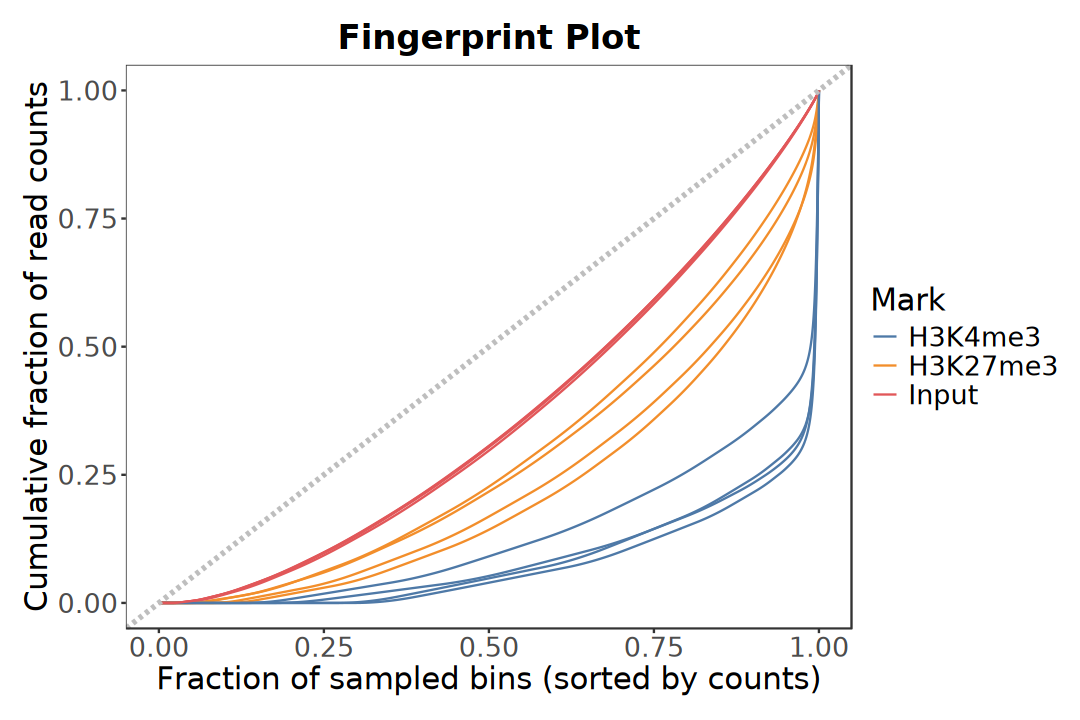

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = fraction_bins, y = fraction_reads, group = Sample)) +
    geom_line(aes(color = Mark)) +
    geom_abline(
        slope = 1, intercept = 0, color = "gray", 
        linetype = "dashed", linewidth = 1.2) +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(
        title = "Fingerprint Plot",
        x = "Fraction of sampled bins (sorted by counts)", 
        y = "Cumulative fraction of read counts") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing.x = unit(0, "lines"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). TSS Enrichment Score

In [15]:
compute_tss_score <- function(
    matrix_file, sample, bs = 10, flank = 2000, verbose = TRUE) {

    mat <- matrix_file |> 
        read.table(header = FALSE, sep = "\t", skip = 3) |>
        as.matrix()

    profile <- colMeans(mat, na.rm = TRUE)
    flank_bins <- as.integer(100 / bs)

    background <- mean(c(head(profile, flank_bins), tail(profile, flank_bins)))

    norm_profile <- profile / background

    center_bin <- as.integer(flank / bs)
    tss_score <- mean(norm_profile[center_bin:(center_bin + 1)])
    if (verbose) {
        message(sample, " TSS Enrichment Score: ", round(tss_score, 2))
    }

    data.frame(
        Position = -flank + (seq_along(profile) - 0.5) * bs, 
        Signal = profile, 
        Sample = sample, 
        TSS_Score = tss_score, 
        Label = paste0(sample, " (Score: ", round(tss_score, 2), ")")
    )
}

In [16]:
matrix_files <- file.path(data_dir, "02_output_chipseq", "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [17]:
profiles_list <- purrr::imap(matrix_files, compute_tss_score)

BMC_Ints11_KO_rep1_H3K27me3 TSS Enrichment Score: 1.42

BMC_Ints11_KO_rep1_H3K4me3 TSS Enrichment Score: 6.91

BMC_Ints11_KO_rep1_Input TSS Enrichment Score: 0.98

BMC_Ints11_KO_rep2_H3K27me3 TSS Enrichment Score: 1.55

BMC_Ints11_KO_rep2_H3K4me3 TSS Enrichment Score: 8.11

BMC_Ints11_KO_rep2_Input TSS Enrichment Score: 1.02

BMC_Ints11_WT_rep1_H3K27me3 TSS Enrichment Score: 1.54

BMC_Ints11_WT_rep1_H3K4me3 TSS Enrichment Score: 7.37

BMC_Ints11_WT_rep1_Input TSS Enrichment Score: 1

BMC_Ints11_WT_rep2_H3K27me3 TSS Enrichment Score: 1.64

BMC_Ints11_WT_rep2_H3K4me3 TSS Enrichment Score: 8.44

BMC_Ints11_WT_rep2_Input TSS Enrichment Score: 1.04



In [18]:
profile_df <- do.call(rbind, profiles_list) |>
    separate(
        Sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Genotype, Mark, Replicate) |>
    mutate(
        Sample = forcats::fct_inorder(as.character(Sample)), 
        Label = sub("BMC_Ints11_(.*)", "\\1", Label), 
        Label = forcats::fct_inorder(as.character(Label)))

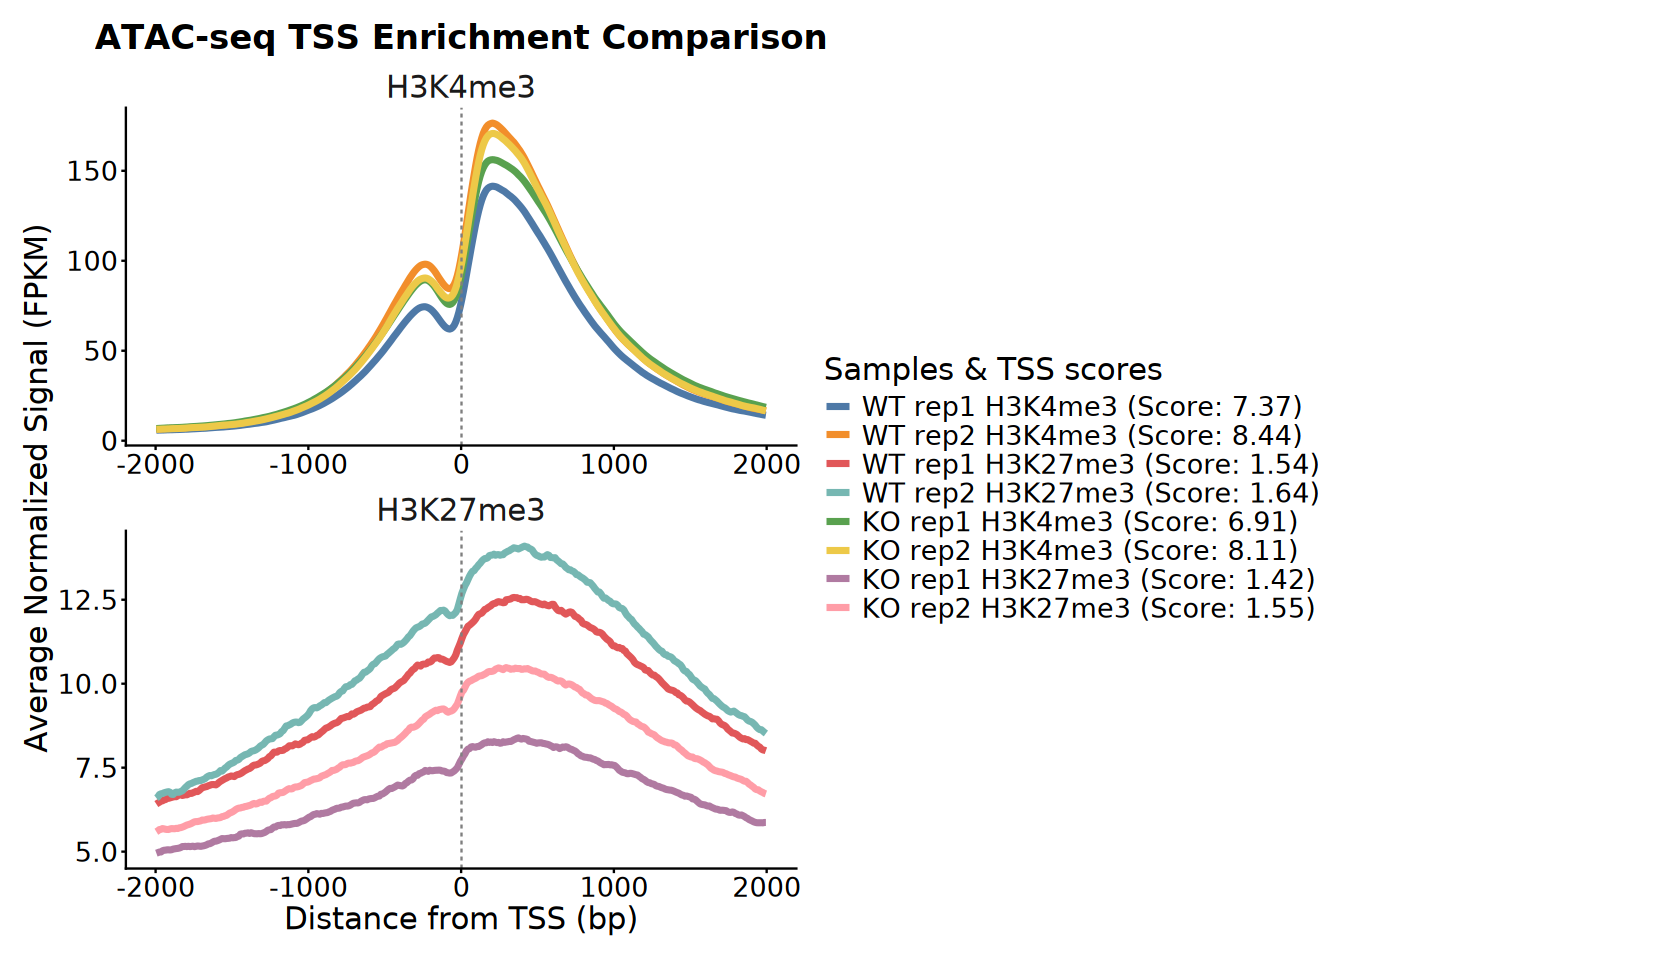

In [19]:
options(repr.plot.width = 14, repr.plot.height = 8)

profile_df |>
    filter(Mark != "Input") |>
ggplot(aes(x = Position, y = Signal)) +
    geom_line(aes(color = Label), linewidth = 1.5) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "gray50") +
    facet_wrap(~ Mark, scales = "free", ncol = 1) +
    ggthemes::scale_color_tableau(
        palette = "Tableau 10", labels = function(x) gsub("_", " ", x)) +
    guides(color = guide_legend(ncol = 1)) +
    labs(
        title = "ATAC-seq TSS Enrichment Comparison",
        color = "Samples & TSS scores",
        x = "Distance from TSS (bp)",
        y = "Average Normalized Signal (FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 15, 1, 1), "line"),
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Peak Width

In [20]:
EFFECTIVE_GENOME_SIZE <- seqinfo(genome) |>
    keepStandardChromosomes() |>
    dropSeqlevels(c("chrM")) |>
    seqlengths() |>
    sum()

In [21]:
peaks_stats <- map_dfr(names(peaks_list), function(idx) {
    peaks <- peaks_list[[idx]]
    data.frame(
        sample = idx, 
        number_peak = length(peaks),
        min_width = min(width(peaks)),
        max_width = max(width(peaks)),
        mean_width = mean(width(peaks)),
        median_width = median(width(peaks)),
        genome_coverage = sum(width(peaks))
    )
}) |> 
    mutate(
        genome_coverage = round(
            genome_coverage / EFFECTIVE_GENOME_SIZE * 100, 2))

peaks_stats

sample,number_peak,min_width,max_width,mean_width,median_width,genome_coverage
<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>
BMC_Ints11_KO_rep1_H3K27me3,20926,205,18330,876.4149,428,0.67
BMC_Ints11_KO_rep1_H3K4me3,38037,137,12579,1124.3563,641,1.57
BMC_Ints11_KO_rep2_H3K27me3,30021,197,57315,959.9163,388,1.06
BMC_Ints11_KO_rep2_H3K4me3,29913,155,12634,1164.3779,744,1.28
BMC_Ints11_WT_rep1_H3K27me3,51992,195,41079,844.9939,357,1.61
BMC_Ints11_WT_rep1_H3K4me3,33857,144,12047,1052.7500,638,1.31
BMC_Ints11_WT_rep2_H3K27me3,35077,194,63012,1020.7862,378,1.31
BMC_Ints11_WT_rep2_H3K4me3,32008,149,13224,1142.0394,715,1.34


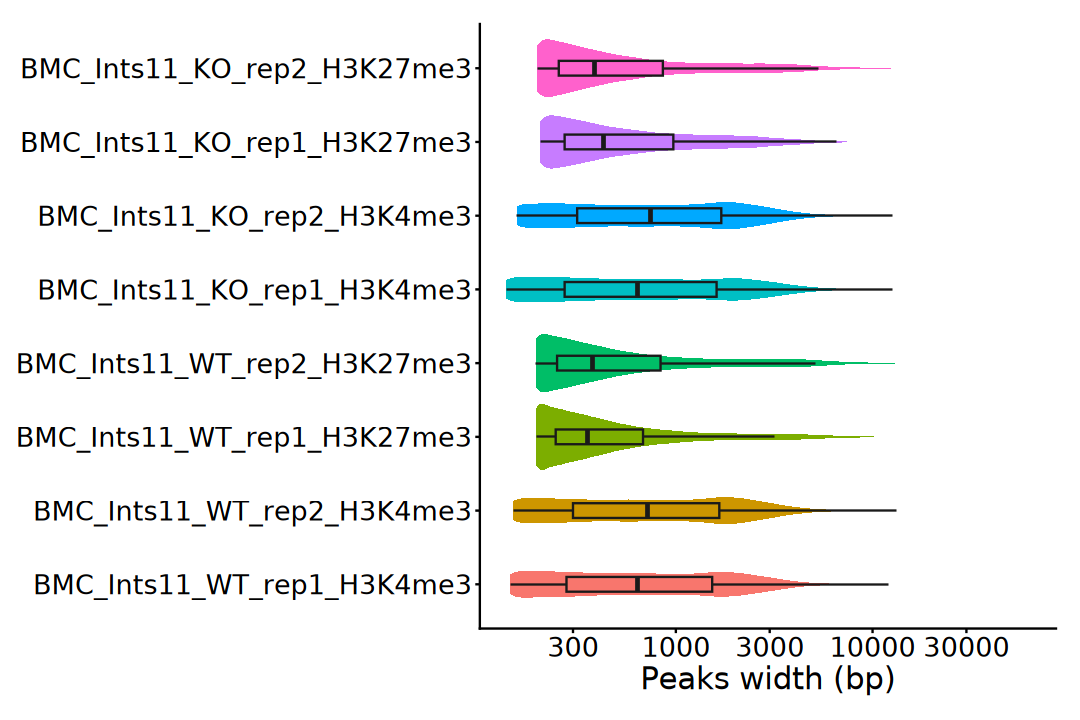

In [22]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_dfr(names(peaks_list), function(idx) {
    tibble(sample = idx, width = width(peaks_list[[idx]]))
}) |> 
    mutate(sample = factor(sample, levels = levels(profile_df$Sample))) |>
ggplot(aes(x = sample, y = width, fill = sample)) +
    geom_violin(trim = TRUE, color = NA) +
    geom_boxplot(width = 0.2, color = "grey10", outliers = FALSE) +
    scale_y_log10() +
    coord_flip() +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(x = NULL, y = "Peaks width (bp)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 6). Replicate Consistency

In [23]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list)), 
    ignore.strand = TRUE) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks(ignore.strand = ignore.strand)

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [24]:
overlap_summary <- names(peaks_list) |>
    data.frame(sample = _) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample") |>
    split(~ Genotype + Mark, drop = TRUE) |>
    purrr::imap_dfr(function(df, group_name) {
        group <- unique(df$Genotype)
        mark  <- unique(df$Mark)
        summarize_peak_overlaps(
            peaks_list[rownames(df)]) |>
            mutate(Mark = mark, Genotype = group, .before = 1)
    })

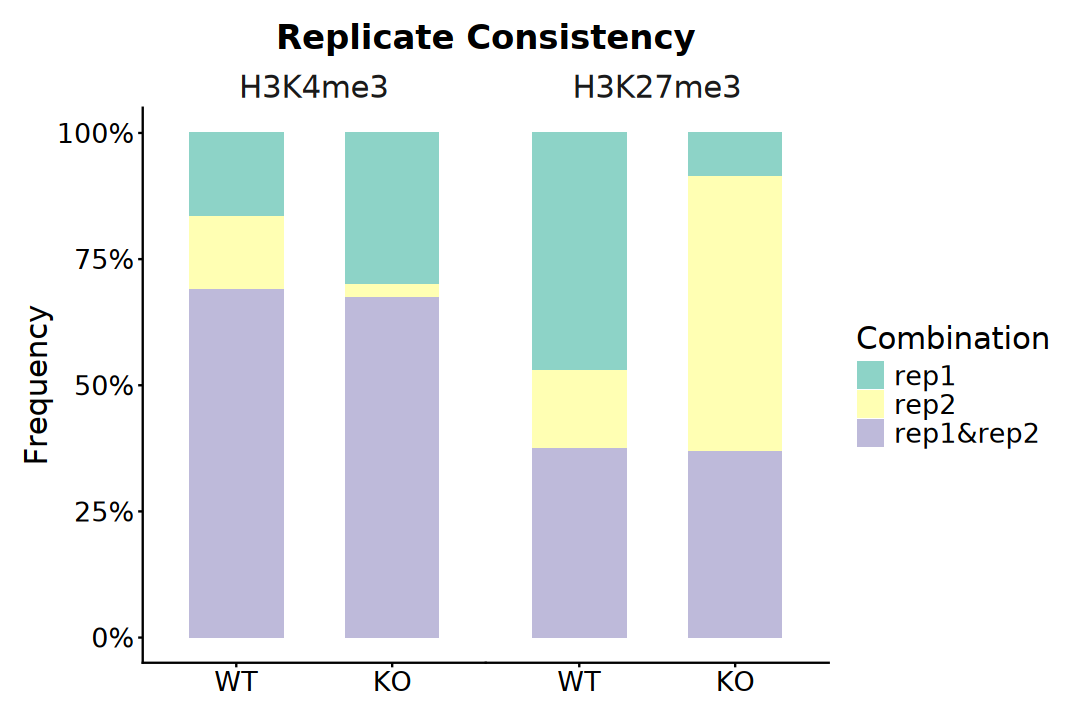

In [25]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(overlap_summary, aes(x = Genotype, y = Counts, fill = Combination)) +
    geom_bar(stat = "identity", position = "fill", width = 0.6) +
    facet_wrap(~ Mark, nrow = 1, strip.position = "top") +
    scale_y_continuous(labels = scales::percent_format()) +
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = NULL, y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"),
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [26]:
signal_mat <- file.path(
    data_dir, "02_output_chipseq", "09_count", "bins_10kb.counts.tsv") |>
    read_tsv(comment = "", show_col_types = FALSE) |>
    rename_with(~ stringr::str_remove_all(.x, "^#|'")) |>
    unite("pos", chr, start, end, sep = "_") |>
    column_to_rownames("pos") |>
    as.matrix()

In [27]:
dim(signal_mat)

keep <- rowSums(!is.finite(signal_mat)) == 0L & rowSums(signal_mat != 0) > 0L

signal_mat <- signal_mat[keep, , drop = FALSE]

dim(signal_mat)

[1] 273121     12

[1] 261647     12

In [28]:
coldata <- data.frame(sample = colnames(signal_mat)) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample")

In [29]:
pca <- signal_mat |> log1p() |> scale() |> t() |>
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(pca$sdev^2 / sum(pca$sdev^2) * 100, 2)

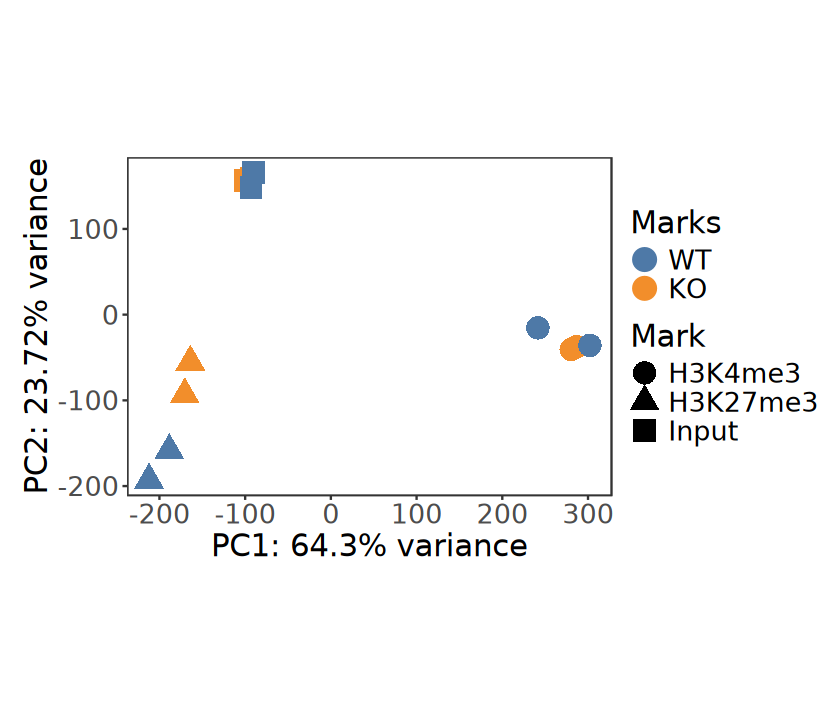

In [30]:
options(repr.plot.width = 7, repr.plot.height = 6)

pca$x |>
    as.data.frame() |>
    rownames_to_column(var = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
ggplot(aes(PC1, PC2, color = Genotype, shape = Mark)) +
    geom_point(size = 6) +
    coord_fixed() +
    ggthemes::scale_color_tableau("Tableau 10") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    labs(color = "Marks") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [31]:
ac <- dplyr::select(coldata, Mark, Replicate, Genotype)

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(coldata$Genotype)),
    levels(coldata$Genotype))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(coldata$Replicate)),
    levels(coldata$Replicate))
mark_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(coldata$Mark)),
    levels(coldata$Mark))

anno_colors <- list(
    Genotype = group_colors,
    Replicate = replicate_colors, 
    Mark = mark_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [32]:
cor_mat <- cor(signal_mat, method = "spearman")

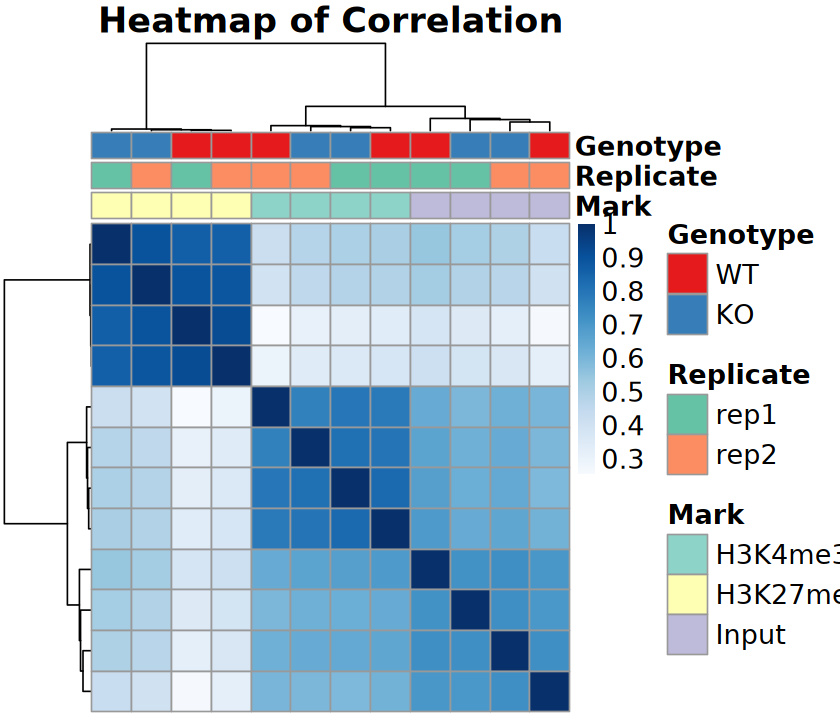

In [33]:
options(repr.plot.width = 7, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [34]:
signal_norm <- signal_mat |> log1p() |> scale()

bin_var <- matrixStats::rowVars(signal_norm)

top_idx <- kit::topn(bin_var, n = 2000L, decreasing = TRUE)

selected <- top_idx[bin_var[top_idx] > 0]

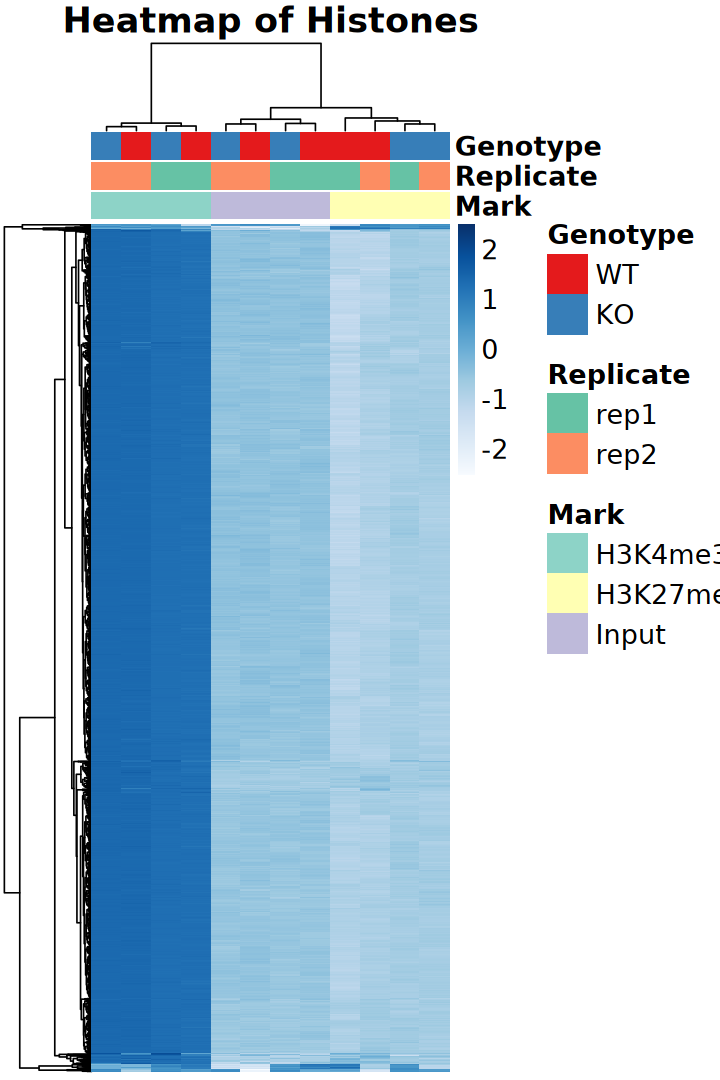

In [35]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    signal_norm[selected, ], 
    scale = "row", 
    col = colors, 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    show_colnames = FALSE, 
    show_rownames = FALSE, 
    fontsize = 16, 
    main = "Heatmap of Histones"
)

# 5. Peak Annotation

### ChIPseeker

In [36]:
suppressPackageStartupMessages(library(ChIPseeker))

In [37]:
# Downstream within 3kb
feature_order <- c(
    "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
    "Downstream", "Intergenic"
)

peaks_annotated_list <- lapply(
    peaks_list, 
    annotatePeak, 
    TxDb = txdb, 
    level = "transcript", 
    tssRegion = c(-2000, 500), 
    genomicAnnotationPriority = feature_order, 
    verbose = FALSE
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>."


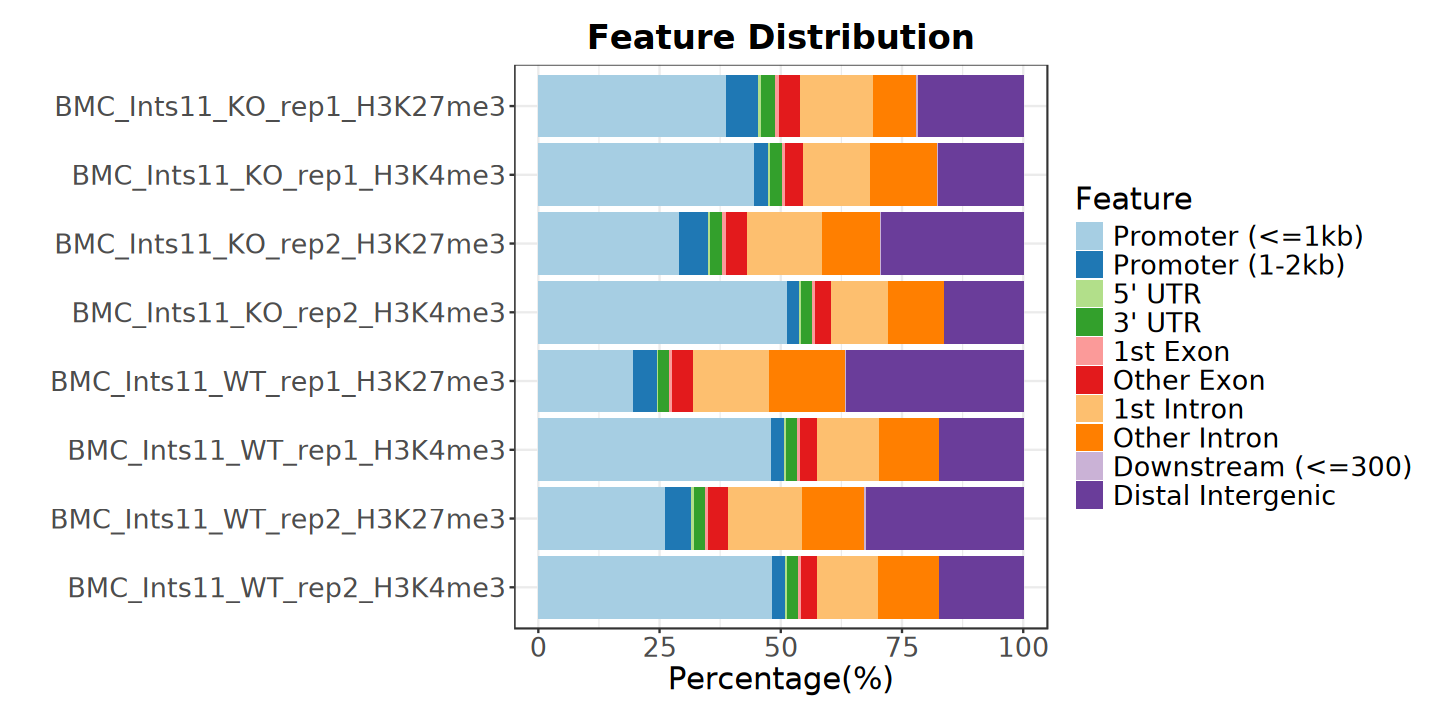

In [38]:
options(repr.plot.width = 12, repr.plot.height = 6)

plotAnnoBar(peaks_annotated_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

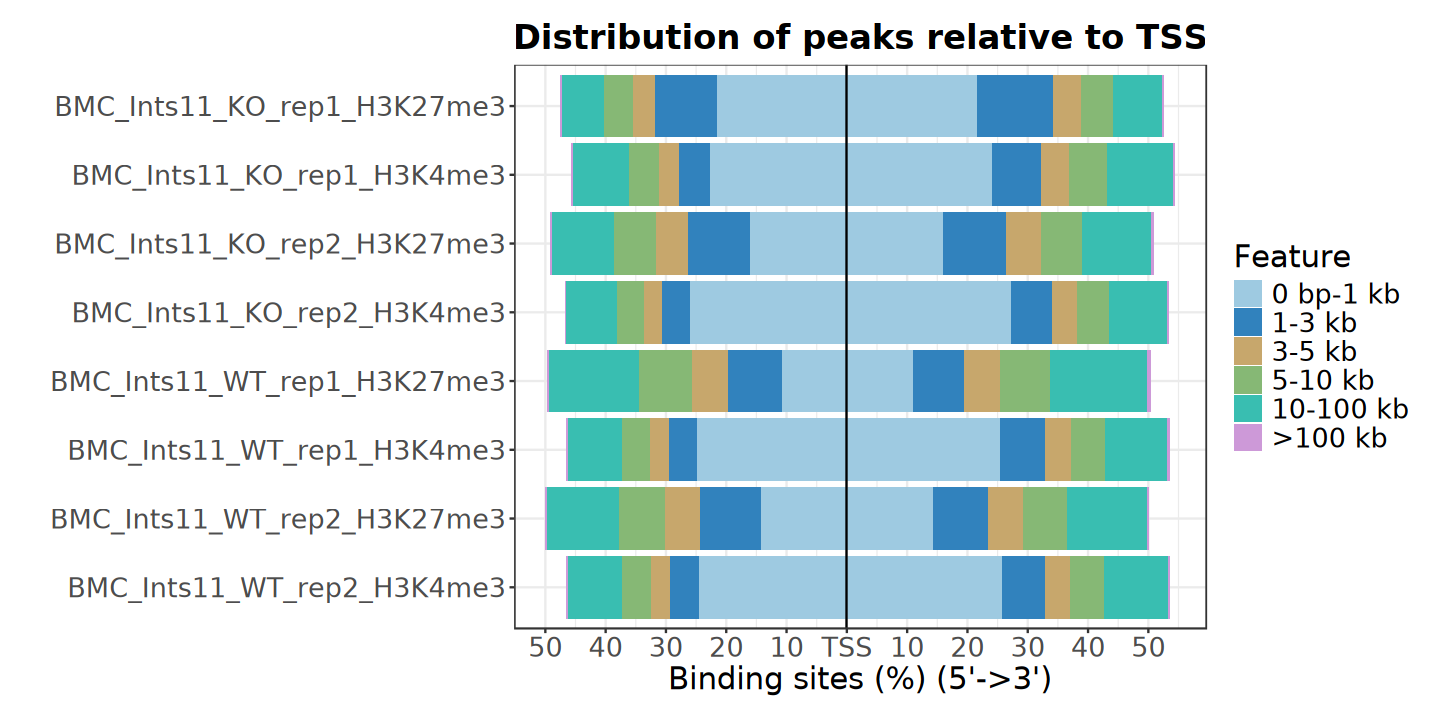

In [39]:
options(repr.plot.width = 12, repr.plot.height = 6)

plotDistToTSS(
    peaks_annotated_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 6. Histone Modification Profiles

## 1). [deepTools](https://github.com/deeptools/deeptools)

## 2). EnrichedHeatmap

In [40]:
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [41]:
GENES <- genes(txdb)

In [42]:
# ~ 40 minutes
gene_mat_list <- lapply(
    signals_list, 
    normalizeToMatrix, 
    GENES, 
    value_column = "score", 
    mean_mode = "w0", 
    extend = 2000, 
    w = 50, 
    target_ratio = 0.4, 
    background = 0, 
    smooth = FALSE
)

In [43]:
sample_order <- levels(profile_df$Sample)

In [44]:
gene_mat_list <- gene_mat_list[sample_order]

In [45]:
gene_order <- order(
    enriched_score(gene_mat_list[["BMC_Ints11_WT_rep1_H3K4me3"]]),
    decreasing = TRUE
)

In [46]:
mark_colors <- ggthemes::tableau_color_pal("Tableau 20")(
    length(gene_mat_list)) |> 
    setNames(names(gene_mat_list)
)

color_fun <- lapply(names(gene_mat_list), function(mark) {
    limit <- gene_mat_list[[mark]] |>
        quantile(0.99, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, limit), c("#FFFFFF", mark_colors[[mark]]))
})

names(color_fun) <- names(gene_mat_list)

In [47]:
ht_list <- lapply(names(gene_mat_list), function(mark) {
    EnrichedHeatmap(
        gene_mat_list[[mark]], 
        name = mark, 
        column_title = mark, 
        col = color_fun[[mark]], 
        cluster_rows = FALSE, 
        row_order = gene_order, 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        width = unit(4, "cm"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = mark_colors[mark]), 
                axis_param = list(gp = gpar(fontsize = 10))
            ), 
            height = unit(3, "cm"), 
            show_legend = FALSE
        ), 
        show_heatmap_legend = TRUE, 
        heatmap_legend_param = list(
            title = "FRKM", 
            direction = "horizontal", 
            title_position = "topcenter", 
            legend_width = unit(4, "cm")
        ), 
        use_raster = TRUE)
})

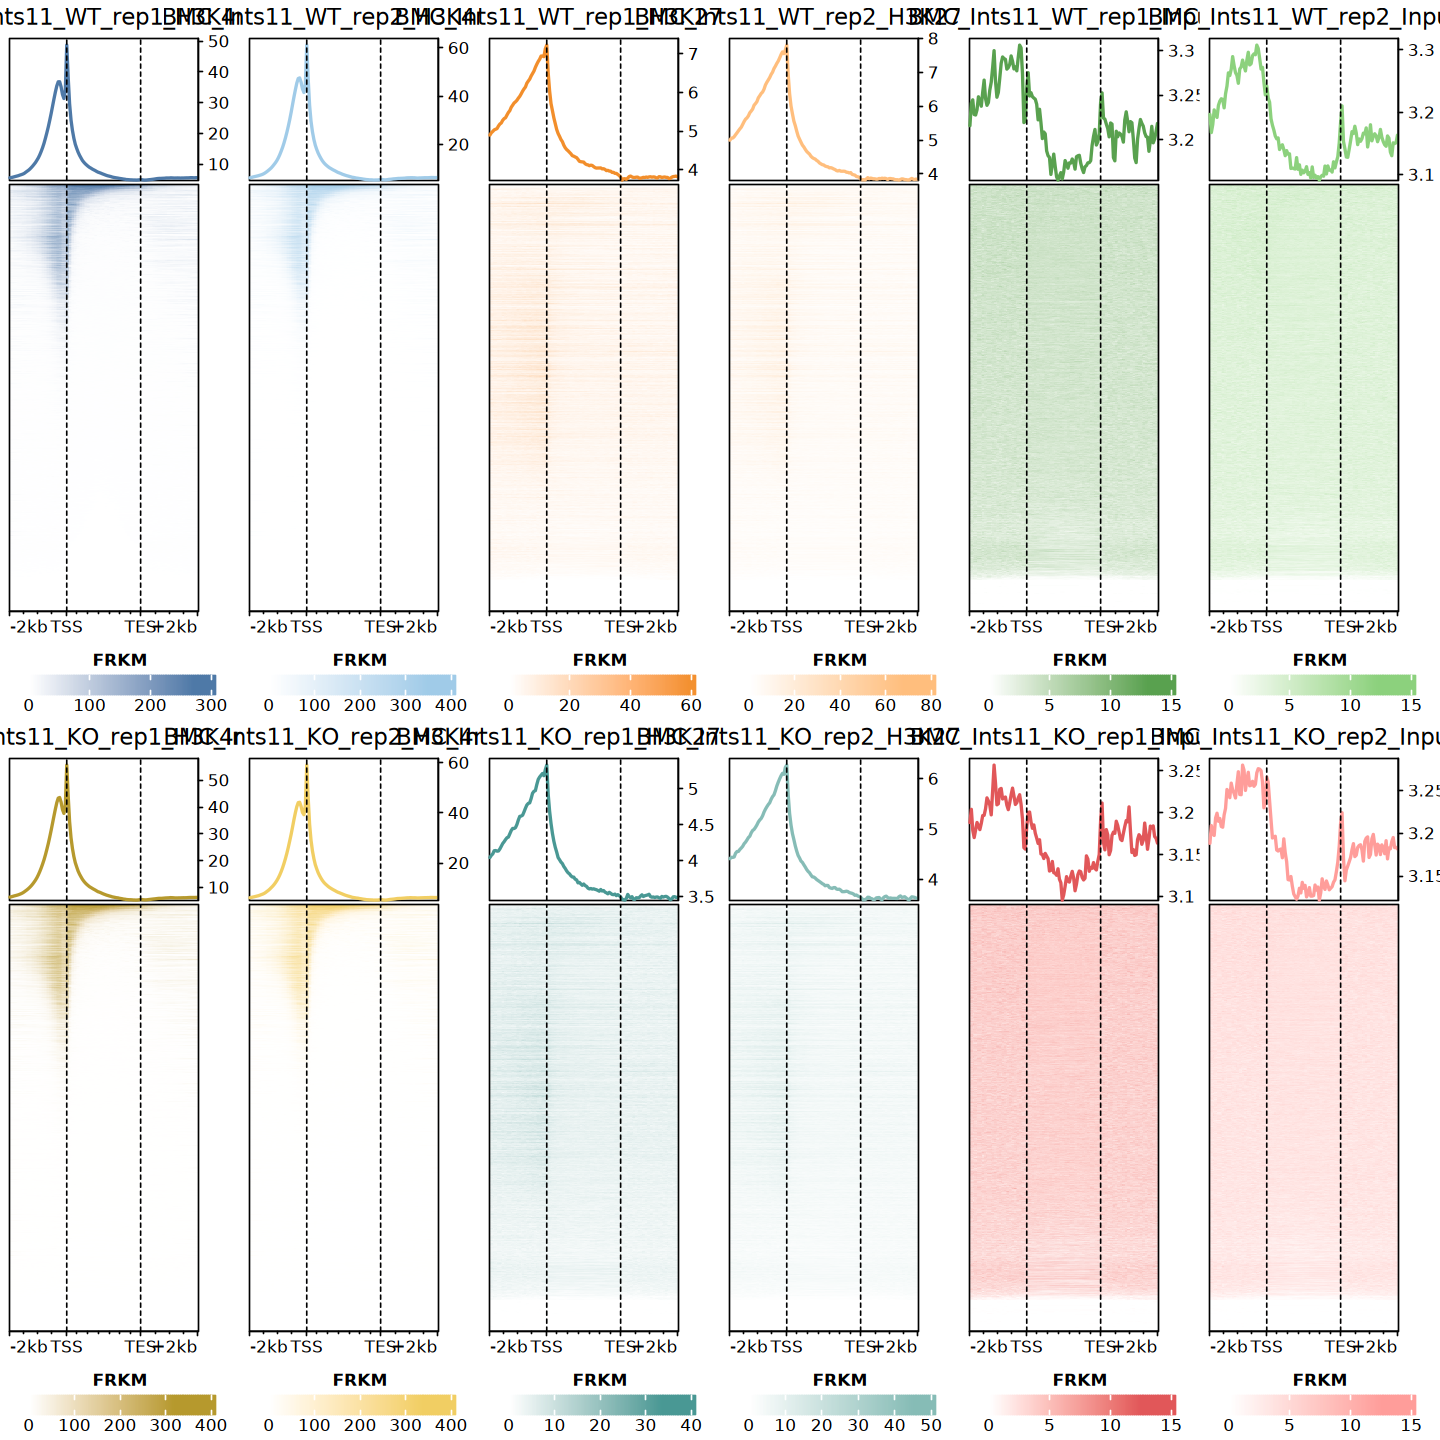

In [48]:
options(repr.plot.width = 12, repr.plot.height = 12)

grid.newpage()

pushViewport(viewport(layout = grid.layout(nrow = 2, ncol = 6)))

for (i in seq_along(ht_list)) {
    pushViewport(viewport(
        layout.pos.row = (i - 1L) %/% 6L + 1L,
        layout.pos.col = (i - 1L) %% 6L + 1L
    ))

    draw(
        ht_list[[i]],
        newpage = FALSE,
        heatmap_legend_side = "bottom"
    )

    popViewport()
}

popViewport()

In [49]:
profiles_df <- purrr::imap_dfr(
    lapply(gene_mat_list, colMeans, na.rm = TRUE),
    function(signal, sample) {
        data.frame(
            Position = seq_along(signal),
            Sample = sample,
            Signal = as.numeric(signal))
}) |>
    separate(
        Sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate))

In [50]:
mat <- gene_mat_list[[1L]]
target_index <- attr(mat, "target_index")

tss_position <- min(target_index) - 0.5
tes_position <- max(target_index) + 0.5

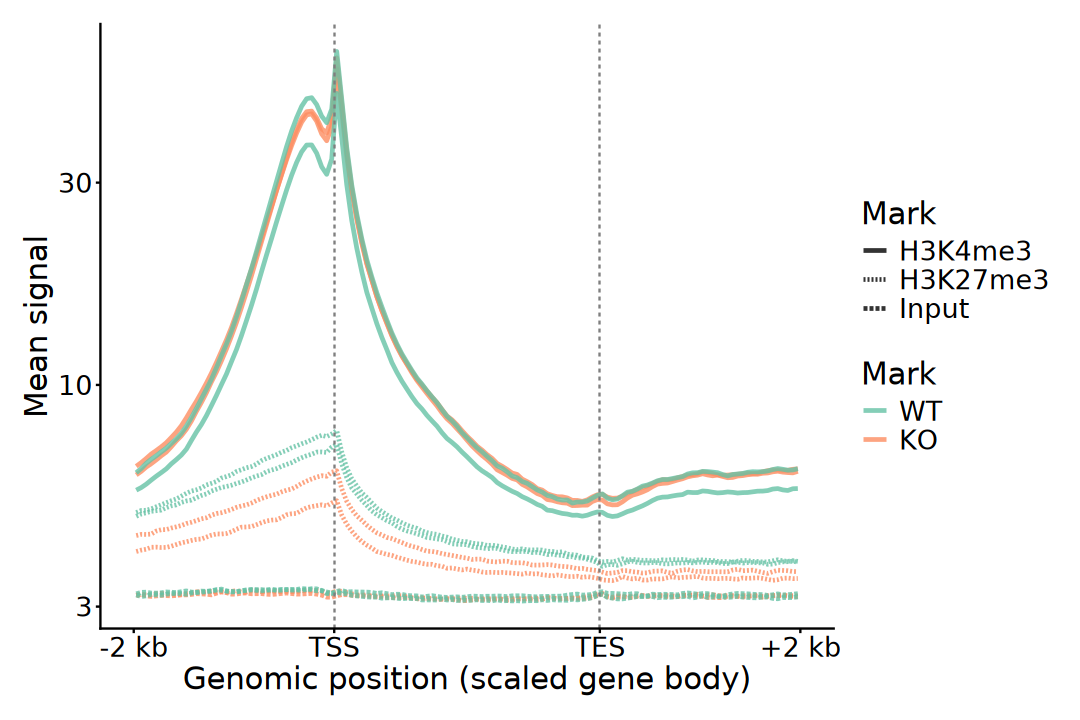

In [51]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Signal, group = Sample)) +
    geom_line(
        aes(color = Genotype, linetype = Mark), 
        linewidth = 1, alpha = 0.8) +
    geom_vline(
        xintercept = c(tss_position, tes_position), 
        linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        limits = c(0.5, ncol(mat) + 0.5),
        breaks = c(0.5, tss_position, tes_position, ncol(mat) + 0.5),
        labels = c("-2 kb", "TSS", "TES", "+2 kb")) +
    scale_y_log10() +
    scale_color_brewer(palette = "Set2") +
    labs(
        x = "Genomic position (scaled gene body)", 
        y = "Mean signal", 
        color = "Mark") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 7. Differential Histone Regions

> Notes:
> 1. Define the Analysis Region
> 2. Obtain the Counts Matrix
> 3. Normalization
> 4. Differential Analysis

In [52]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## a). Manual

> 1. Define the Analysis Region
>     - Peak-based methods
>         - Specific regions of the genome (Promoter, Enhancer, Gene body)
>         - Identify consensus peaks
>     - Window-based approaches
> 2. Obtain the **Raw Counts** Matrix
>     - deeptools, multiBamSummary (PE: fargment, `--samFlagInclude 64`)
>     - bedtools, multicov (?PE: reads)
> 3. Library Size (Normalization)
>     - Total number of mapped reads (default)
>     - Sum of mapped reads in the peaks
> 4. Differential Analysis
>     - DESeq2 (default)
>     - edgeR

In [53]:
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))

### H3K4me3

In [54]:
raw_counts <- file.path(
    data_dir, "02_output_chipseq", "05_peaks_pooled", 
    "BMC_Ints11_H3K4me3.featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE) |>
    column_to_rownames("Geneid") |>
    dplyr::select(matches("BMC")) |>
    as.matrix()

colnames(raw_counts) <- colnames(raw_counts) |>
    sub("^02_output_chipseq/04_bam/(.*?).bam", "\\1", x = _) |>
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 26559     8

In [55]:
coldata <- colnames(raw_counts) |>
    data.frame(sample = _) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Genotype, Mark, Replicate) |>
    column_to_rownames("sample")

coldata$BioID <- interaction(
    coldata$Genotype, coldata$Replicate, sep = "_", drop = TRUE)

coldata$is_chip <- as.integer(coldata$Mark != "Input")
coldata$ko_chip <- as.integer(coldata$Genotype == "KO") * coldata$is_chip

coldata

,Cell,Gene,Genotype,Replicate,Mark,BioID,is_chip,ko_chip
,<chr>,<chr>,<fct>,<fct>,<fct>,<fct>,<int>,<int>
BMC_Ints11_WT_rep1_H3K4me3,BMC,Ints11,WT,rep1,H3K4me3,WT_rep1,1,0
BMC_Ints11_WT_rep2_H3K4me3,BMC,Ints11,WT,rep2,H3K4me3,WT_rep2,1,0
BMC_Ints11_WT_rep1_Input,BMC,Ints11,WT,rep1,Input,WT_rep1,0,0
BMC_Ints11_WT_rep2_Input,BMC,Ints11,WT,rep2,Input,WT_rep2,0,0
BMC_Ints11_KO_rep1_H3K4me3,BMC,Ints11,KO,rep1,H3K4me3,KO_rep1,1,1
BMC_Ints11_KO_rep2_H3K4me3,BMC,Ints11,KO,rep2,H3K4me3,KO_rep2,1,1
BMC_Ints11_KO_rep1_Input,BMC,Ints11,KO,rep1,Input,KO_rep1,0,0
BMC_Ints11_KO_rep2_Input,BMC,Ints11,KO,rep2,Input,KO_rep2,0,0


In [56]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts[, rownames(coldata), drop = FALSE],
    colData = coldata,
    design = ~ BioID + is_chip + ko_chip
)

  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function



In [57]:
# Library sizes were estimated using the total number of uniquely mapped reads.
library_sizes <- file.path(
    data_dir, "02_output_chipseq", "09_count", "library_sizes.tsv"
) |>
    read.table(header = TRUE, row.names = 1)

library_sizes <- library_sizes[colnames(dds), ]

names(library_sizes) <- colnames(dds)

# Geometric mean
sf <- library_sizes / exp(mean(log(library_sizes)))
sizeFactors(dds) <- sf

paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")

BMC_Ints11_WT_rep1_H3K4me3: 0.9097
BMC_Ints11_WT_rep2_H3K4me3: 0.7609
BMC_Ints11_WT_rep1_Input: 1.0534
BMC_Ints11_WT_rep2_Input: 1.2161
BMC_Ints11_KO_rep1_H3K4me3: 1.142
BMC_Ints11_KO_rep2_H3K4me3: 0.7337
BMC_Ints11_KO_rep1_Input: 1.1628
BMC_Ints11_KO_rep2_Input: 1.1574


In [58]:
dds <- DESeq(dds)
resultsNames(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"                "BioID_KO_rep1_vs_WT_rep1"
[3] "BioID_WT_rep2_vs_WT_rep1" "BioID_KO_rep2_vs_WT_rep1"
[5] "is_chip"                  "ko_chip"

In [59]:
res <- results(
    dds, name = "ko_chip", lfcThreshold = logfc_cutoff, alpha = p_cutoff
)

summary(res)


out of 26559 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 0, 0%
LFC < -1.00 (down) : 0, 0%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [60]:
deseq2_result <- res |> as.data.frame() |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |> 
            factor(levels = c("Gain", "Loss", "NS"))) |>
    rownames_to_column(var = "peak_id") |>
    separate(
        peak_id, into = c("chr", "start", "end"), 
        sep = ":|-", remove = TRUE) |>
    GRanges()

deseq2_result

GRanges object with 26559 ranges and 7 metadata columns:
            seqnames          ranges strand |  baseMean      logFC     lfcSE
               <Rle>       <IRanges>  <Rle> | <numeric>  <numeric> <numeric>
      [1] GL456216.1     13411-14415      * |   99.4677  1.0639825  0.761537
      [2] GL456216.1     15190-17616      * |  659.3155  0.0265048  0.404744
      [3] GL456233.1     38243-39684      * |  250.4680  0.2344889  0.544871
      [4] GL456233.1   159375-160327      * |   79.4069 -0.5961604  0.747071
      [5] JH584295.1       1362-1976      * |   48.9453 -0.7260755  0.734125
      ...        ...             ...    ... .       ...        ...       ...
  [26555]       chrY   897159-899296      * |  310.8963  -0.294515  0.532405
  [26556]       chrY 1009158-1009585      * |   24.9142  -0.751117  0.993981
  [26557]       chrY 1009700-1011928      * |  430.6591  -0.758578  0.472643
  [26558]       chrY 1244067-1246320      * |  400.9746   0.275937  0.475411
  [26559]       chr

In [61]:
res_tab <- table(deseq2_result$result)

message(
    "Differential histone peaks summary (DEseq2):\n",
    "---------------------------------------------------\n",
    "Gain (higher histone) : ", res_tab["Gain"], "\n",
    "Loss (lower histone)  : ", res_tab["Loss"], "\n",
    "Not significant       : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential histone peaks summary (DEseq2):
---------------------------------------------------
Gain (higher histone) : 0
Loss (lower histone)  : 0
Not significant       : 26559
---------------------------------------------------



### H3K27me3

In [62]:
raw_counts <- file.path(
    data_dir, "02_output_chipseq", "05_peaks_pooled", 
    "BMC_Ints11_H3K27me3.featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE) |>
    column_to_rownames("Geneid") |>
    dplyr::select(matches("BMC")) |>
    as.matrix()

colnames(raw_counts) <- colnames(raw_counts) |>
    sub("^02_output_chipseq/04_bam/(.*?).bam", "\\1", x = _) |>
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 17794     8

In [63]:
coldata <- colnames(raw_counts) |>
    data.frame(sample = _) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Genotype, Mark, Replicate) |>
    column_to_rownames("sample")

coldata$BioID <- interaction(
    coldata$Genotype, coldata$Replicate, sep = "_", drop = TRUE)

coldata$is_chip <- as.integer(coldata$Mark != "Input")
coldata$ko_chip <- as.integer(coldata$Genotype == "KO") * coldata$is_chip

coldata

,Cell,Gene,Genotype,Replicate,Mark,BioID,is_chip,ko_chip
,<chr>,<chr>,<fct>,<fct>,<fct>,<fct>,<int>,<int>
BMC_Ints11_WT_rep1_H3K27me3,BMC,Ints11,WT,rep1,H3K27me3,WT_rep1,1,0
BMC_Ints11_WT_rep2_H3K27me3,BMC,Ints11,WT,rep2,H3K27me3,WT_rep2,1,0
BMC_Ints11_WT_rep1_Input,BMC,Ints11,WT,rep1,Input,WT_rep1,0,0
BMC_Ints11_WT_rep2_Input,BMC,Ints11,WT,rep2,Input,WT_rep2,0,0
BMC_Ints11_KO_rep1_H3K27me3,BMC,Ints11,KO,rep1,H3K27me3,KO_rep1,1,1
BMC_Ints11_KO_rep2_H3K27me3,BMC,Ints11,KO,rep2,H3K27me3,KO_rep2,1,1
BMC_Ints11_KO_rep1_Input,BMC,Ints11,KO,rep1,Input,KO_rep1,0,0
BMC_Ints11_KO_rep2_Input,BMC,Ints11,KO,rep2,Input,KO_rep2,0,0


In [64]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts[, rownames(coldata), drop = FALSE],
    colData = coldata,
    design = ~ BioID + is_chip + ko_chip
)

  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function



In [65]:
# Library sizes were estimated using the total number of uniquely mapped reads.
library_sizes <- file.path(
    data_dir, "02_output_chipseq", "09_count", "library_sizes.tsv") |>
    read.table(header = TRUE, row.names = 1)

library_sizes <- library_sizes[colnames(dds), ]

names(library_sizes) <- colnames(dds)

# Geometric mean
sf <- library_sizes / exp(mean(log(library_sizes)))
sizeFactors(dds) <- sf

paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")

BMC_Ints11_WT_rep1_H3K27me3: 0.8116
BMC_Ints11_WT_rep2_H3K27me3: 0.7931
BMC_Ints11_WT_rep1_Input: 1.0794
BMC_Ints11_WT_rep2_Input: 1.2461
BMC_Ints11_KO_rep1_H3K27me3: 0.8216
BMC_Ints11_KO_rep2_H3K27me3: 0.9947
BMC_Ints11_KO_rep1_Input: 1.1915
BMC_Ints11_KO_rep2_Input: 1.186


In [66]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [67]:
res <- results(
    dds, name = "ko_chip", lfcThreshold = logfc_cutoff, alpha = p_cutoff
)

summary(res)


out of 17794 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 0, 0%
LFC < -1.00 (down) : 0, 0%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [68]:
deseq2_result <- res |> as.data.frame() |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |> 
            factor(levels = c("Gain", "Loss", "NS"))) |>
    rownames_to_column(var = "peak_id") |>
    separate(
        peak_id, into = c("chr", "start", "end"), 
        sep = ":|-", remove = TRUE) |>
    GRanges()

deseq2_result

GRanges object with 17794 ranges and 7 metadata columns:
          seqnames              ranges strand |  baseMean      logFC     lfcSE
             <Rle>           <IRanges>  <Rle> | <numeric>  <numeric> <numeric>
      [1]     chr1     3669265-3672785      * |  168.9633 -0.5019220  0.409102
      [2]     chr1     4487801-4500001      * |  824.1708 -0.5411511  0.274062
      [3]     chr1     4500093-4502900      * |   80.0556 -0.7251889  0.451658
      [4]     chr1     4570909-4572435      * |   70.6946 -0.0561959  0.514419
      [5]     chr1     5016222-5016641      * |   14.0200 -0.0739948  0.978761
      ...      ...                 ...    ... .       ...        ...       ...
  [17790]     chrX 166583011-166584568      * |   39.0236  -0.570417  0.687541
  [17791]     chrX 166584649-166587304      * |   75.9657  -0.349340  0.507410
  [17792]     chrX 168123055-168124271      * |   30.0210  -1.255411  0.779391
  [17793]     chrX 168794489-168798034      * |  147.8520  -0.364612  0.48

In [69]:
res_tab <- table(deseq2_result$result)

message(
    "Differential histone peaks summary (DEseq2):\n",
    "---------------------------------------------------\n",
    "Gain (higher histone) : ", res_tab["Gain"], "\n",
    "Loss (lower histone)  : ", res_tab["Loss"], "\n",
    "Not significant       : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential histone peaks summary (DEseq2):
---------------------------------------------------
Gain (higher histone) : 0
Loss (lower histone)  : 0
Not significant       : 17794
---------------------------------------------------



In [70]:
# dhmp_peaks <- list(
#     Gain = deseq2_result[deseq2_result$result == "Gain", ], 
#     Loss = deseq2_result[deseq2_result$result == "Loss", ])

In [71]:
# dhmp_peaks <- lapply(
#     dhmp_peaks, annotatePeak, tssRegion = c(-2000, 500), 
#     TxDb = txdb, level = "gene", verbose = FALSE,
#     genomicAnnotationPriority = c(
#         "Promoter", "Exon", "Intron", "Intergenic"))

In [72]:
# options(repr.plot.width = 9, repr.plot.height = 6)

# plotAnnoBar(dhmp_peaks) +
#     theme_bw() +
#     theme(
#         plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
#         plot.margin = unit(c(1, 1, 1, 1), "line"), 
#         legend.position = "right", 
#         legend.title = element_text(size = 18), 
#         legend.text = element_text(size = 16),
#         axis.title = element_text(size = 18), 
#         axis.text = element_text(size = 16))

## b). DiffBind

> Differential analysis
> 1. DESeq2
> 2. edgeR

In [73]:
suppressPackageStartupMessages(library(DiffBind))
suppressPackageStartupMessages(library(BiocParallel))

In [74]:
bam_files <- file.path(data_dir, "02_output_chipseq", "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bam$", "\\1", basename(.x)))

peaks_files <- file.path(data_dir, "02_output_chipseq", "05_peaks") |>
    list.files(pattern = "peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

In [75]:
sample_sheet <- data.frame(SampleID = names(peaks_files)) |>
    separate(
        SampleID, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    dplyr::filter(Mark == "H3K27me3") |>
    mutate(
        Tissue = Cell, 
        Factor = Mark, 
        Condition = Genotype, 
        Treatment = Mark, 
        Replicate = as.numeric(sub("rep", "", Replicate)), 
        bamReads = unname(bam_files[SampleID]), 
        ControlID = sub("_H3K27me3$", "_Input", SampleID), 
        bamControl = unname(bam_files[ControlID]), 
        Peaks = unname(peaks_files[SampleID]),
        PeakCaller = "narrow") |>
    dplyr::select(
        SampleID, Tissue, Factor, Condition, Treatment, Replicate, 
        bamReads, bamControl, ControlID, Peaks, PeakCaller)

sample_sheet |> dplyr::select(-any_of(c("Peaks", "bamReads", "bamControl")))

SampleID,Tissue,Factor,Condition,Treatment,Replicate,ControlID,PeakCaller
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
BMC_Ints11_KO_rep1_H3K27me3,BMC,H3K27me3,KO,H3K27me3,1,BMC_Ints11_KO_rep1_Input,narrow
BMC_Ints11_KO_rep2_H3K27me3,BMC,H3K27me3,KO,H3K27me3,2,BMC_Ints11_KO_rep2_Input,narrow
BMC_Ints11_WT_rep1_H3K27me3,BMC,H3K27me3,WT,H3K27me3,1,BMC_Ints11_WT_rep1_Input,narrow
BMC_Ints11_WT_rep2_H3K27me3,BMC,H3K27me3,WT,H3K27me3,2,BMC_Ints11_WT_rep2_Input,narrow


In [76]:
sample_sheet |> write.csv(
    file.path(
        data_dir, "02_output_chipseq", "01_stats", "diffbind_sample.csv"), 
    quote = FALSE, row.names = FALSE)

In [77]:
dbObj <- dba(sampleSheet = file.path(
    data_dir, "02_output_chipseq", "01_stats", "diffbind_sample.csv")
)

dbObj

BMC_Ints11_KO_rep1_H3K27me3 BMC H3K27me3 KO H3K27me3 1 narrow

BMC_Ints11_KO_rep2_H3K27me3 BMC H3K27me3 KO H3K27me3 2 narrow

BMC_Ints11_WT_rep1_H3K27me3 BMC H3K27me3 WT H3K27me3 1 narrow

BMC_Ints11_WT_rep2_H3K27me3 BMC H3K27me3 WT H3K27me3 2 narrow



4 Samples, 22729 sites in matrix (58183 total):
                           ID Tissue   Factor Condition Treatment Replicate
1 BMC_Ints11_KO_rep1_H3K27me3    BMC H3K27me3        KO  H3K27me3         1
2 BMC_Ints11_KO_rep2_H3K27me3    BMC H3K27me3        KO  H3K27me3         2
3 BMC_Ints11_WT_rep1_H3K27me3    BMC H3K27me3        WT  H3K27me3         1
4 BMC_Ints11_WT_rep2_H3K27me3    BMC H3K27me3        WT  H3K27me3         2
  Intervals
1     21141
2     30363
3     52554
4     35510

In [78]:
dbObj <- dba.blacklist(
    dbObj, 
    blacklist = DBA_BLACKLIST_MM10, 
    greylist = FALSE
)

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1546 of 139568 intervals.

Removed: 658 merged (of 58183) and 266 (of 22729) consensus.



In [79]:
# Force registration of a multi-core environment with only 4 workers (cores).
# register(MulticoreParam(workers = 4))

# Set the number of CPU cores for parallel processing to 6
print(dbObj$config$cores)
dbObj$config$cores <- 4
# Check (or return) the current status of parallel execution (TRUE/FALSE)
print(dbObj$config$RunParallel)

[1] 16
[1] TRUE


In [ ]:
# Count reads in binding site intervals
# (4 cores: ~ 7 min, memory consumption, 32G?)
dbObj <- dba.count(
    dbObj, 
    minOverlap = 2, 
    summits = FALSE, 
    bUseSummarizeOverlaps = TRUE, 
    bParallel = TRUE
)

dbObj

4 Samples, 22463 sites in matrix:
                           ID Tissue   Factor Condition Treatment Replicate
1 BMC_Ints11_KO_rep1_H3K27me3    BMC H3K27me3        KO  H3K27me3         1
2 BMC_Ints11_KO_rep2_H3K27me3    BMC H3K27me3        KO  H3K27me3         2
3 BMC_Ints11_WT_rep1_H3K27me3    BMC H3K27me3        WT  H3K27me3         1
4 BMC_Ints11_WT_rep2_H3K27me3    BMC H3K27me3        WT  H3K27me3         2
     Reads FRiP
1 21518625 0.10
2 26052077 0.13
3 21256290 0.18
4 20772341 0.19

In [81]:
# Normalization
dbObj <- dba.normalize(
    dbObj, 
     method = DBA_DESEQ2, 
    normalize = DBA_NORM_LIB, 
    library = DBA_LIBSIZE_FULL, 
    background = FALSE
)

In [82]:
# Sets up contrasts for differential binding affinity analysis
dbObj <- dba.contrast(
    dbObj, 
    design = "~ Condition", 
    contrast = c("Condition", "KO", "WT"), 
    minMembers = 2
)

dbObj

Computing results names...



4 Samples, 22463 sites in matrix:
                           ID Tissue   Factor Condition Treatment Replicate
1 BMC_Ints11_KO_rep1_H3K27me3    BMC H3K27me3        KO  H3K27me3         1
2 BMC_Ints11_KO_rep2_H3K27me3    BMC H3K27me3        KO  H3K27me3         2
3 BMC_Ints11_WT_rep1_H3K27me3    BMC H3K27me3        WT  H3K27me3         1
4 BMC_Ints11_WT_rep2_H3K27me3    BMC H3K27me3        WT  H3K27me3         2
     Reads FRiP
1 21518625 0.10
2 26052077 0.13
3 21256290 0.18
4 20772341 0.19

Design: [~ Condition] | 1 Contrast:
     Factor Group Samples Group2 Samples2
1 Condition    KO       2     WT        2

In [83]:
# Perform differential binding affinity analysis
dbObj <- dba.analyze(
    dbObj, 
    method = DBA_DESEQ2, 
    bGreylist = FALSE
)

dba.show(dbObj, bContrasts = TRUE)

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,KO,2,WT,2,6464


In [84]:
# Generate a report for a differential binding affinity analysis
diffbind_result <- dba.report(
    dbObj, 
    contrast = 1, 
    method = DBA_DESEQ2, 
    th = 1, 
    bUsePval = FALSE, 
    fold = 0, 
    bCounts = TRUE, 
    precision = 0
)

diffbind_result$result = case_when(
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold >  logfc_cutoff ~ "Gain",
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold < -logfc_cutoff ~ "Loss",
    TRUE ~ "NS") |> 
    factor(levels = c("Gain", "Loss", "NS")
)

diffbind_result

GRanges object with 22463 ranges and 11 metadata columns:
        seqnames              ranges strand |      Conc   Conc_KO   Conc_WT
           <Rle>           <IRanges>  <Rle> | <numeric> <numeric> <numeric>
   7153    chr15   98721459-98725765      * |   7.86210   6.55558   8.53630
   8089    chr16   97463432-97465428      * |   7.48616   8.48616   0.00000
  15235     chr5   23828908-23833024      * |   7.75900   6.49098   8.42328
   9572    chr18   74957331-74963143      * |   8.36092   7.25876   8.97839
    735     chr1 133162535-133165363      * |   7.59399   6.56733   8.18773
    ...      ...                 ...    ... .       ...       ...       ...
   7187    chr15   99218353-99218809      * |   3.78252   3.77740   3.78763
  20596     chr8 122227921-122228448      * |   3.79446   3.79871   3.79019
   5036    chr13   51408427-51408711      * |   2.55816   2.55102   2.56527
   8667    chr17   43358183-43358548      * |   3.73272   3.73393   3.73150
  13540     chr4     4022971-4

In [85]:
res_tab <- table(diffbind_result$result)

message(
    "Differential histone peaks summary (DiffBind):\n",
    "---------------------------------------------------\n",
    "Gain (higher histone) : ", res_tab["Gain"], "\n",
    "Loss (lower histone)  : ", res_tab["Loss"], "\n",
    "Not significant       : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential histone peaks summary (DiffBind):
---------------------------------------------------
Gain (higher histone) : 3
Loss (lower histone)  : 340
Not significant       : 22120
---------------------------------------------------



## c). csaw
 
> Differential analysis
> 1. edgeR

In [86]:
suppressPackageStartupMessages(library(csaw))
suppressPackageStartupMessages(library(rtracklayer))

In [87]:
bam_files <- file.path(data_dir, "02_output_chipseq", "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bam$", "\\1", basename(.x)))

bam_files <- bam_files[grep("H3K27me3|Input", names(bam_files))]

paste(names(bam_files), basename(bam_files), sep = ": ") |> cat(sep = "\n")

BMC_Ints11_KO_rep1_H3K27me3: BMC_Ints11_KO_rep1_H3K27me3.bam
BMC_Ints11_KO_rep1_Input: BMC_Ints11_KO_rep1_Input.bam
BMC_Ints11_KO_rep2_H3K27me3: BMC_Ints11_KO_rep2_H3K27me3.bam
BMC_Ints11_KO_rep2_Input: BMC_Ints11_KO_rep2_Input.bam
BMC_Ints11_WT_rep1_H3K27me3: BMC_Ints11_WT_rep1_H3K27me3.bam
BMC_Ints11_WT_rep1_Input: BMC_Ints11_WT_rep1_Input.bam
BMC_Ints11_WT_rep2_H3K27me3: BMC_Ints11_WT_rep2_H3K27me3.bam
BMC_Ints11_WT_rep2_Input: BMC_Ints11_WT_rep2_Input.bam


In [88]:
blacklist <- import(blacklist_file)

In [89]:
# Filtering out low-quality reads
param <- readParam(
    pe = "none", 
    minq = NA, 
    dedup = FALSE, 
    restrict = paste0("chr", c(1:19, "X", "Y")), 
    discard = blacklist
)

param

    Extracting reads in single-end mode
    Duplicate removal is turned off 
    No minimum threshold is set on the mapping score
    Reads are extracted from both strands
    Read extraction is limited to 21 sequences
    Reads in 3435 regions will be discarded

In [90]:
# Compute correlation coefficients between reads (~ 5 min)
corr_reads <- correlateReads(bam_files[1], max.dist = 1000, param = param)

# Estimate the average reads length by maximizing the cross-correlations.
message("Average of reads size: ", maximizeCcf(corr_reads))

Average of reads size: 142



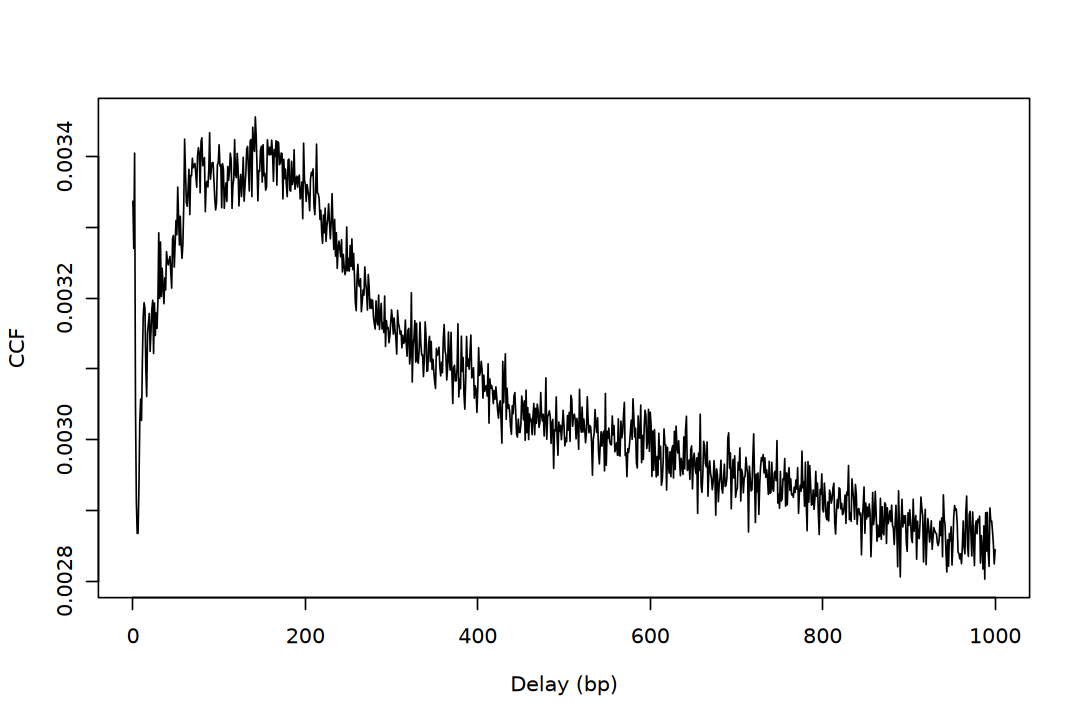

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(0:1000, corr_reads, type = "l", ylab = "CCF", xlab = "Delay (bp)")

In [ ]:
# Count reads overlapping each window (~ 7 min)
# improve efficiency: spacing = (width + ext) / 2
wins_counts <- windowCounts(
    bam_files, 
    width = 200, 
    spacing = 100, 
    ext = 150, 
    shift = 0,
    filter = 10, 
    bin = FALSE, 
    param = param
)

wins_counts

# region_counts <- regionCounts(
#     bam_files, regions = target_region, ext = 150,
#     filter = 10, param = param)

class: RangedSummarizedExperiment 
dim: 23134200 8 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames(8): BMC_Ints11_KO_rep1_H3K27me3 BMC_Ints11_KO_rep1_Input ...
  BMC_Ints11_WT_rep2_H3K27me3 BMC_Ints11_WT_rep2_Input
colData names(4): bam.files totals ext rlen

In [93]:
# Filtering windows by abundance (~ 7 min)
bins_counts <- windowCounts(
    bam_files, 
    bin = TRUE, 
    width = 10000, 
    ext = 150, 
    param = param
)

bins_counts

class: RangedSummarizedExperiment 
dim: 248861 8 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames(8): BMC_Ints11_KO_rep1_H3K27me3 BMC_Ints11_KO_rep1_Input ...
  BMC_Ints11_WT_rep2_H3K27me3 BMC_Ints11_WT_rep2_Input
colData names(4): bam.files totals ext rlen

In [94]:
chip_idx <- c(5, 7, 1, 3)
input_idx <- c(6, 8, 2, 4)

chip_wins <- wins_counts[, chip_idx]
input_wins <- wins_counts[, input_idx]

chip_bins <- bins_counts[, chip_idx]
input_bins <- bins_counts[, input_idx]

In [95]:
control_scale <- scaleControlFilter(chip_bins, input_bins)

input_stats <- filterWindowsControl(
    chip_wins,
    input_wins,
    scale.info = control_scale
)

keep <- is.finite(input_stats$filter) &
    input_stats$filter > log2(4)

print(table(keep))

keep
   FALSE     TRUE 
22819920   314280 


In [96]:
chip_wins_filtered <- chip_wins[keep, ]
chip_wins_filtered

class: RangedSummarizedExperiment 
dim: 314280 4 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames(4): BMC_Ints11_WT_rep1_H3K27me3 BMC_Ints11_WT_rep2_H3K27me3
  BMC_Ints11_KO_rep1_H3K27me3 BMC_Ints11_KO_rep2_H3K27me3
colData names(4): bam.files totals ext rlen

In [97]:
# Normalizing for technical biases
# 1. Eliminating composition biases (edgeR' TMM)
# 2. Eliminating efficiency biases
chip_wins_filtered <- normFactors(
    chip_bins, 
    se.out = chip_wins_filtered
)

chip_wins_filtered

class: RangedSummarizedExperiment 
dim: 314280 4 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames(4): BMC_Ints11_WT_rep1_H3K27me3 BMC_Ints11_WT_rep2_H3K27me3
  BMC_Ints11_KO_rep1_H3K27me3 BMC_Ints11_KO_rep2_H3K27me3
colData names(5): bam.files totals ext rlen norm.factors

In [98]:
dgel <- asDGEList(chip_wins_filtered)

In [99]:
colnames(dgel$counts) <- colnames(chip_wins_filtered)
rownames(dgel$samples) <- colnames(chip_wins_filtered)
dgel$samples$group <- factor(
    c("WT", "WT", "KO", "KO"), levels = c("WT", "KO")
)

dgel$samples

,group,lib.size,norm.factors
,<fct>,<int>,<dbl>
BMC_Ints11_WT_rep1_H3K27me3,WT,20909046,0.9005257
BMC_Ints11_WT_rep2_H3K27me3,WT,20407859,0.9493832
BMC_Ints11_KO_rep1_H3K27me3,KO,21128055,1.1176334
BMC_Ints11_KO_rep2_H3K27me3,KO,25592747,1.0465573


In [100]:
design <- model.matrix(~ group, data = dgel$samples)
print(design)

                            (Intercept) groupKO
BMC_Ints11_WT_rep1_H3K27me3           1       0
BMC_Ints11_WT_rep2_H3K27me3           1       0
BMC_Ints11_KO_rep1_H3K27me3           1       1
BMC_Ints11_KO_rep2_H3K27me3           1       1
attr(,"assign")
[1] 0 1
attr(,"contrasts")
attr(,"contrasts")$group
[1] "contr.treatment"



In [101]:
dgel <- estimateDisp(dgel, design)
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [102]:
chip_wins_merged <- mergeResults(
    chip_wins_filtered, 
    qlf$table, 
    tol = 1000L, 
    merge.args = list(max.width = 5000)
)

In [103]:
csaw_result <- chip_wins_merged$combined |>
    as.data.frame() |>
    dplyr::rename(padj = FDR, pvalue = PValue, logFC = rep.logFC) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |>
            factor(levels = c("Gain", "Loss", "NS")))

head(csaw_result)

,num.tests,num.up.logFC,num.down.logFC,pvalue,padj,direction,rep.test,logFC,result
,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<int>,<dbl>,<fct>
1,29,0,1,0.048936694,0.07275064,down,27,-1.7061951,NS
2,40,0,25,0.010821512,0.03172922,down,43,-1.2956031,Loss
3,43,0,27,0.002199698,0.02001671,down,103,-1.4650735,Loss
4,22,0,14,0.040474897,0.06378136,down,113,-0.9155786,NS
5,12,0,0,0.294301040,0.32219076,down,142,-0.5687527,NS
6,36,0,0,0.133993916,0.16154314,down,148,-0.9536104,NS


In [104]:
res_tab <- table(csaw_result$result)

message(
    "Differential histone peaks summary (csaw):\n",
    "---------------------------------------------------\n",
    "Gain (higher histone) : ", res_tab["Gain"], "\n",
    "Loss (lower histone)  : ", res_tab["Loss"], "\n",
    "Not significant       : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential histone peaks summary (csaw):
---------------------------------------------------
Gain (higher histone) : 0
Loss (lower histone)  : 8876
Not significant       : 7355
---------------------------------------------------



# 8. Bivalent Domains

# 9. Genome Browser Snapshots

In [105]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [ ]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53178
# $dataprovider: UCSC
# $species: Homo sapiens
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for hg38
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 9606
# $genome: hg38
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/hg38/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53178"]]' 

In [ ]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [ ]:
# Hoxa
genome_id = "mm10"

target_region <- "chr7:27090000-27230000"

target_region <- str_match(target_region, "^([^:]+):(\\d+)-(\\d+)$") |>
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), end = as.numeric(V4)) |>
    column_to_rownames("pos") |>
    GRanges()

chrom <- seqnames(target_region) |> as.character()
region_start <- start(target_region)
region_end <- end(target_region)

target_region

GRanges object with 1 range and 0 metadata columns:
                         seqnames            ranges strand
                            <Rle>         <IRanges>  <Rle>
  chr7:27090000-27230000     chr7 27090000-27230000      *
  -------
  seqinfo: 1 sequence from an unspecified genome; no seqlengths

In [109]:
id_track <- IdeogramTrack(
    chromosome = chrom, 
    genome = genome_id, 
    bands = bands, 
    name = str_to_title(chrom), 
    fontcolor = "black", 
    fontsize = 20
)

scale_track <- GenomeAxisTrack(
    scale = 0.1, 
    col = "black", 
    fontcolor = "black", 
    labelPos = "above", 
    showTitle = FALSE, 
    fontsize = 16,
    distFromAxis = 1, 
    lwd = 1
)

axis_track <- GenomeAxisTrack(
    labelPos = "above", 
    col = "black", 
    fontcolor = "black", 
    exponent = 6, 
    distFromAxis = 0.5, 
    showTitle = FALSE, 
    fontsize = 14, 
    lwd = 2
)

In [110]:
mark_colors <- ggthemes::tableau_color_pal("Tableau 20")(
    length(signals_list)) |> 
    setNames(names(signals_list)
)

In [111]:
signal_tracks <- purrr::imap(signals_list, function(gr, mark) {
    gr <- subsetByOverlaps(
        gr, target_region, ignore.strand = TRUE)

    DataTrack(
        range = gr,
        data = "score",
        name = mark,
        type = "histogram",
        chromosome = chrom,
        genome = genome_id,
        showTitle = TRUE,
        fontsize = 12,
        cex.title = 1,
        cex.axis = 0.8,
        col.title = "black",
        fontcolor.title = "black",
        col.histogram = mark_colors[[mark]],
        fill.histogram = mark_colors[[mark]]
    )
})

In [112]:
gene_track <- GeneRegionTrack(
    txdb, 
    genome = genome_id, 
    chromosome = chrom, 
    start = region_start, 
    end = region_end,
    transcriptAnnotation = "symbol", 
    showId = TRUE, 
    geneSymbol = TRUE, 
    collapseTranscripts = "longest", 
    name = "Gene", 
    col = "grey50", 
    fill = "orange", 
    fontcolor.group = "black", 
    fontsize = 20, 
    fontsize.group = 16, 
    cex.title = 1, 
    rotation.title = 0,
    stacking = "squish"
)

In [113]:
gene_info <- gtf[gtf$type == "gene"]

gene_symbols <- setNames(
    as.character(gene_info$gene_name),
    as.character(gene_info$gene_id)
)

gene_ranges <- ranges(gene_track)
gene_ids <- as.character(gene_ranges$gene)

symbols <- unname(gene_symbols[gene_ids])

missing <- is.na(symbols) | symbols == ""
symbols[missing] <- gene_ids[missing]

gene_ranges$symbol <- symbols
ranges(gene_track) <- gene_ranges

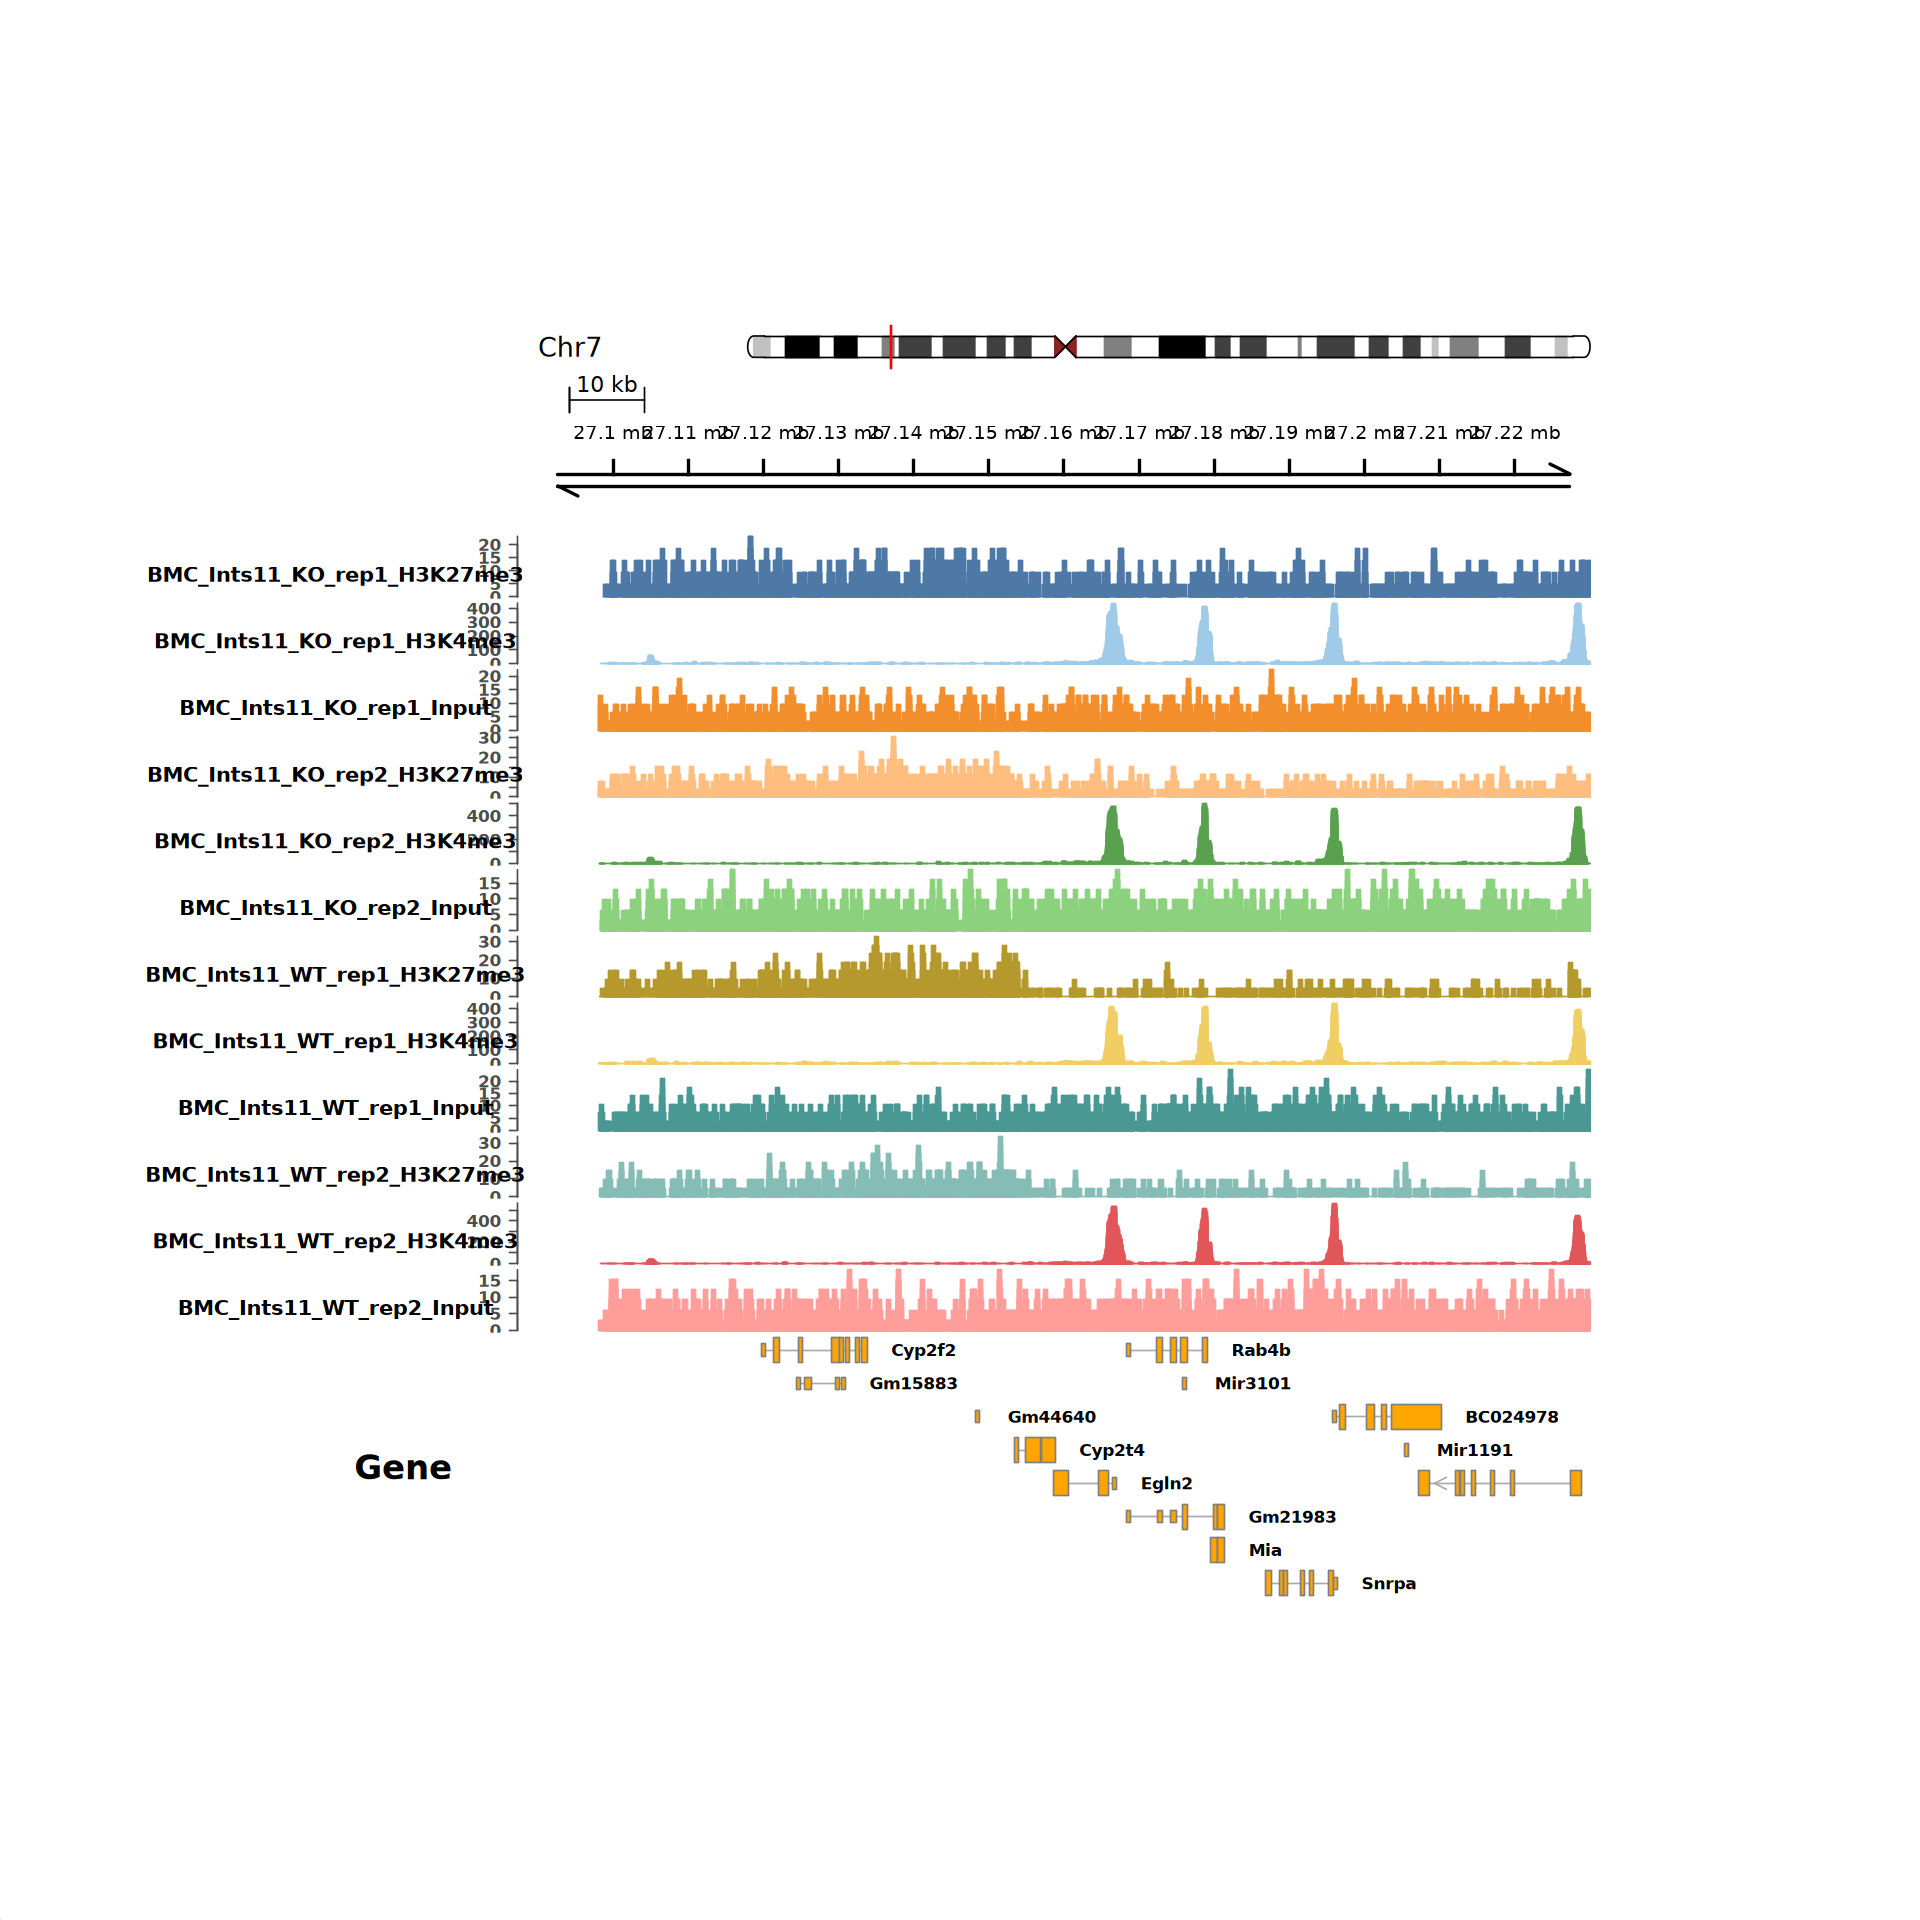

In [114]:
options(repr.plot.width = 16, repr.plot.height = 16)

track_list <- c(
    list(id_track, scale_track, axis_track),
    signal_tracks,
    list(gene_track)
)

plotTracks(
    trackList = track_list, 
    chromosome = chrom, 
    from = region_start, 
    to = region_end, 
    sizes = c(2, 2, 4, rep(2.5, length(signals_list)), 10), 
    background.title = "white", 
    col.title = "black", 
    col.axis = "grey30", 
    reverseStrand = FALSE, 
    rotation.title = 0, 
    title.width = 1, 
    just.group = "right", 
    extend.left = 0, 
    margin = 80
)

# * Reference

> 1. [The csaw Book](https://bioconductor.org/books/release/csawBook/)